# Week 2: RFM & K-Means Customer Segmentation

**Source:**  in local PostgreSQL ()  
**Prerequisite:** Run  in your terminal before executing.

## 1. Portable PostgreSQL Connection & Data Load

In [ ]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sqlalchemy import create_engine

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('PG_USER')}:{os.getenv('PG_PASSWORD')}"
    f"@{os.getenv('PG_HOST')}:{os.getenv('PG_PORT')}/{os.getenv('PG_DB')}"
)

df = pd.read_sql("SELECT * FROM vw_rfm_segments", engine)
print(f"Loaded {len(df):,} customers from vw_rfm_segments")
df.head()

Loaded 4,285 customers from vw_rfm_segments


,customer_id,country,last_purchase,recency,frequency,monetary,total_units,avg_order_value,r_score,f_score,m_score,rfm_score,rfm_segment
0,18102,United Kingdom,2010-12-09 13:44:00,1,89,349164.35,124216,3923.19,4,4,4,12,Champions
1,14646,Netherlands,2010-11-30 16:28:00,10,73,247613.50,170228,3391.97,4,4,4,12,Champions
2,14156,EIRE,2010-12-03 11:48:00,7,91,186832.00,108074,2053.10,4,4,4,12,Champions
3,14911,EIRE,2010-12-09 12:17:00,1,183,140352.54,69624,766.95,4,4,4,12,Champions
4,13694,United Kingdom,2010-12-01 12:12:00,9,94,131443.19,125893,1398.33,4,4,4,12,Champions


## 2. Rule-Based RFM Segment Profile & Revenue Share

,customers,total_revenue,avg_recency,avg_frequency,avg_monetary,customer_pct,revenue_pct
rfm_segment,,,,,,,
Champions,457,4379830.38,7.49,16.06,9583.87,10.67,50.69
Loyal Customers,1334,3092755.92,56.70,5.69,2318.41,31.13,35.80
Hibernating / Lost,1393,429627.77,167.01,1.50,308.42,32.51,4.97
At Risk,398,391012.46,144.42,2.34,982.44,9.29,4.53
Potential Loyalists,703,346430.67,26.76,1.44,492.79,16.41,4.01


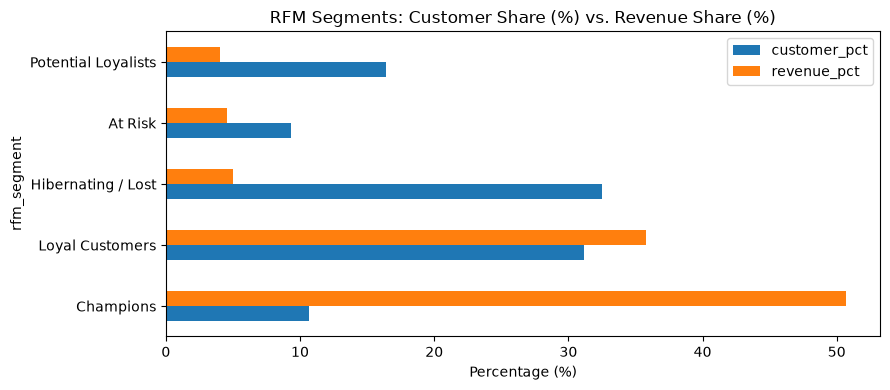

In [2]:
seg_summary = (
    df.groupby("rfm_segment")
    .agg(
        customers=("customer_id", "count"),
        total_revenue=("monetary", "sum"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
    )
    .assign(
        customer_pct=lambda x: (x["customers"] / x["customers"].sum() * 100).round(2),
        revenue_pct=lambda x: (x["total_revenue"] / x["total_revenue"].sum() * 100).round(2),
    )
    .sort_values("total_revenue", ascending=False)
)
display(seg_summary.round(2))

ax = seg_summary[["customer_pct", "revenue_pct"]].plot(kind="barh", figsize=(9, 4))
ax.set_title("RFM Segments: Customer Share (%) vs. Revenue Share (%)")
ax.set_xlabel("Percentage (%)")
plt.tight_layout()
plt.show()

## 3. Log-Transform, Scaling & Optimal k Selection

,k,inertia,silhouette
0,2,6562.7569,0.4227
1,3,4941.7108,0.3283
2,4,3950.9563,0.3331
3,5,3333.7833,0.3187
4,6,2911.7558,0.3123
5,7,2597.6519,0.3067


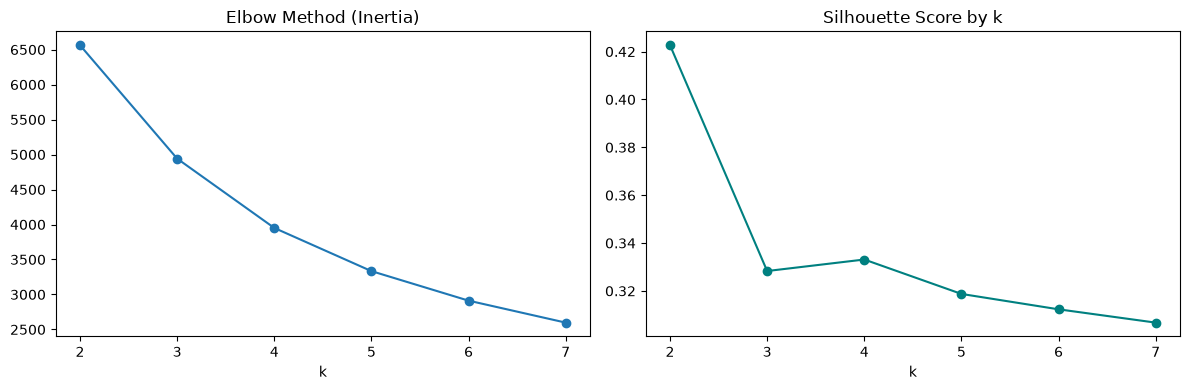

In [3]:
features = df[["recency", "frequency", "monetary"]].copy()
features_log = np.log1p(features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_log)

results = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    results.append(
        {
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X_scaled, labels),
        }
    )

eval_df = pd.DataFrame(results)
display(eval_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(eval_df["k"], eval_df["inertia"], marker="o")
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("k")
axes[1].plot(eval_df["k"], eval_df["silhouette"], marker="o", color="teal")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

## 4. Fit K-Means, Profile Clusters & Cross-Tab vs. RFM

In [4]:
k_opt = 4  # Adjust if another k clearly wins in Section 3
kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
df["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

cluster_profile = (
    df.groupby("kmeans_cluster")
    .agg(
        customers=("customer_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_revenue=("monetary", "sum"),
    )
    .sort_values("avg_monetary", ascending=False)
)
display(cluster_profile.round(2))

print("Cross-Tab: Rule-Based RFM vs. K-Means Cluster")
display(pd.crosstab(df["rfm_segment"], df["kmeans_cluster"], margins=True))

,customers,avg_recency,avg_frequency,avg_monetary,total_revenue
kmeans_cluster,,,,,
3,762,13.76,13.56,7332.92,5587685.98
0,1172,82.09,4.12,1788.76,2096430.42
2,936,22.16,2.11,562.37,526380.42
1,1415,184.14,1.29,303.29,429160.38


Cross-Tab: Rule-Based RFM vs. K-Means Cluster


kmeans_cluster,0,1,2,3,All
rfm_segment,,,,,
At Risk,232,157,9,0,398
Champions,1,0,0,456,457
Hibernating / Lost,40,1177,176,0,1393
Loyal Customers,872,2,154,306,1334
Potential Loyalists,27,79,597,0,703
All,1172,1415,936,762,4285


## 5. Persist  to PostgreSQL & CSV

In [5]:
out_dir = PROJECT_ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(out_dir / "customer_segments_week2.csv", index=False)
df.to_sql("customer_segments", engine, if_exists="replace", index=False)
print("Saved customer_segments to PostgreSQL and data/processed/customer_segments_week2.csv")

Saved customer_segments to PostgreSQL and data/processed/customer_segments_week2.csv
